In [2]:
!mkdir -p /content/drive/MyDrive/rbi_macro
!cp /content/*.xlsx /content/*.XLSX /content/*.py /content/*.csv /content/drive/MyDrive/rbi_macro/
!ls /content/drive/MyDrive/rbi_macro


 build_dataset.py
 macro_monthly.csv
'RBIB Table No. 19 _ Consumer Price Index (Base 2010=100).xlsx'
'RBIB Table No. 23 _ Index of Industrial Production (Base_ 2004-05=100 & 2011-12 &  2022-23).xlsx'
 table40.XLSX


# Chapter 3: look at the data before modelling. Paste into one Colab cell and run.

       repo_rate  cpi_infl  iip_growth
count     111.00    111.00      111.00
mean        5.58      4.67        4.07
std         0.97      1.71       15.26
min         4.00      0.25      -57.31
25%         4.90      3.40        1.56
50%         6.00      4.85        4.12
75%         6.50      5.94        5.54
max         6.50      7.79      133.52

Correlations:
             repo_rate  cpi_infl  iip_growth
repo_rate        1.00     -0.39       -0.02
cpi_infl        -0.39      1.00       -0.07
iip_growth      -0.02     -0.07        1.00

IIP growth, 3 smallest:
 month_end
2020-04-30   -57.3
2020-05-31   -33.4
2020-03-31   -18.7
Name: iip_growth, dtype: float64
IIP growth, 2 largest:
 month_end
2021-04-30    133.5
2021-05-31     27.6
Name: iip_growth, dtype: float64

ADF p-values (large p = the series wanders, no fixed level):
  repo_rate   p = 0.351
  cpi_infl    p = 0.664
  iip_growth  p = 0.000


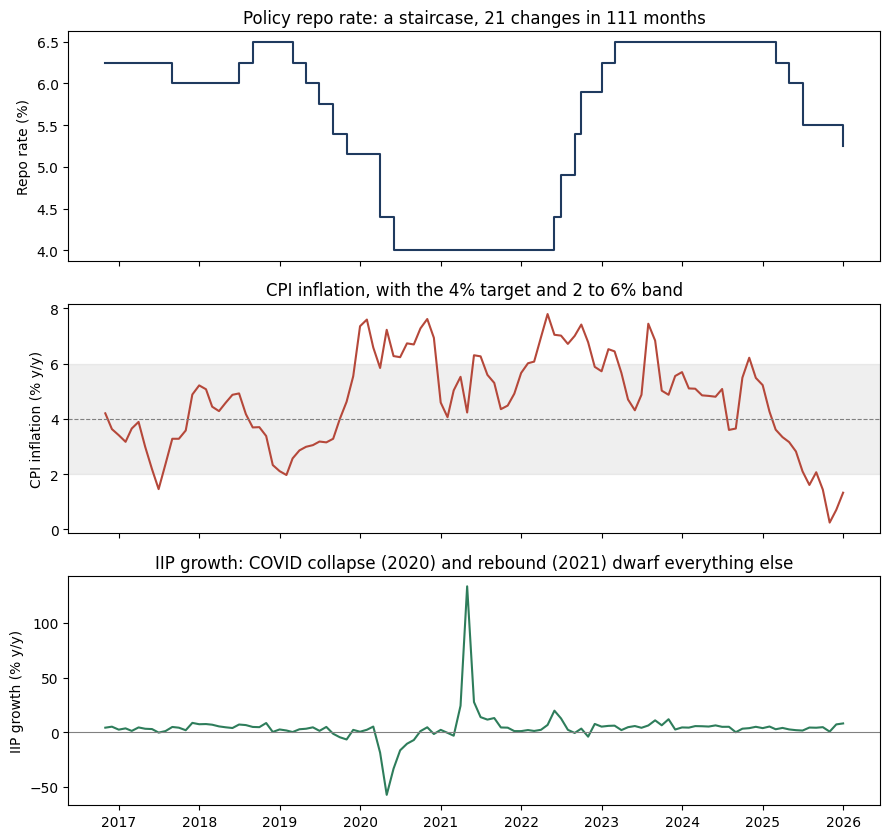

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

m = pd.read_csv('/content/drive/MyDrive/rbi_macro/macro_monthly.csv', parse_dates=['month_end'], index_col='month_end')

print(m[['repo_rate', 'cpi_infl', 'iip_growth']].describe().round(2))
print('\nCorrelations:\n', m[['repo_rate', 'cpi_infl', 'iip_growth']].corr().round(2))
print('\nIIP growth, 3 smallest:\n', m['iip_growth'].nsmallest(3).round(1))
print('IIP growth, 2 largest:\n', m['iip_growth'].nlargest(2).round(1))
print('\nADF p-values (large p = the series wanders, no fixed level):')
for c in ['repo_rate', 'cpi_infl', 'iip_growth']:
    print(f'  {c:11s} p = {adfuller(m[c])[1]:.3f}')

fig, ax = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True)
ax[0].step(m.index, m['repo_rate'], where='post', color='#1F3A5F')
ax[0].set_ylabel('Repo rate (%)'); ax[0].set_title('Policy repo rate: a staircase, 21 changes in 111 months')
ax[1].plot(m.index, m['cpi_infl'], color='#B5483A'); ax[1].axhline(4, ls='--', c='grey', lw=.8)
ax[1].axhspan(2, 6, color='grey', alpha=.12); ax[1].set_ylabel('CPI inflation (% y/y)')
ax[1].set_title('CPI inflation, with the 4% target and 2 to 6% band')
ax[2].plot(m.index, m['iip_growth'], color='#2E7D5B'); ax[2].axhline(0, c='grey', lw=.8)
ax[2].set_ylabel('IIP growth (% y/y)'); ax[2].set_title('IIP growth: COVID collapse (2020) and rebound (2021) dwarf everything else')
plt.tight_layout(); plt.show()


# Chapter 4: first models. Paste into one Colab cell and run.

In [4]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

m = pd.read_csv('/content/drive/MyDrive/rbi_macro/macro_monthly.csv', parse_dates=['month_end'], index_col='month_end')
m['covid'] = ((m.index >= '2020-03-31') & (m.index <= '2021-06-30')).astype(int)   # Mar 2020 - Jun 2021
m['repo_lag'] = m['repo_rate'].shift(1)                                              # last month's repo rate

def fit(y, X, d, label, lags=6):
    d = d.dropna(subset=[y] + X)
    r = sm.OLS(d[y], sm.add_constant(d[X])).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    print(f'\n== {label}  (n={int(r.nobs)}, R2={r.rsquared:.3f}, Durbin-Watson={durbin_watson(r.resid):.2f})')
    print(pd.DataFrame({'coef': r.params, 'se': r.bse, 'p': r.pvalues}).round(3).to_string())
    return r

def long_run(r, var='cpi_infl'):
    """Long-run effect = b / (1 - rho), with a delta-method confidence interval."""
    b, rho = r.params[var], r.params['repo_lag']
    g = pd.Series(0.0, index=r.params.index); g[var] = 1 / (1 - rho); g['repo_lag'] = b / (1 - rho) ** 2
    se = float(np.sqrt(g.values @ r.cov_params().values @ g.values)); est = b / (1 - rho)
    print(f'   long-run effect of inflation = {est:.2f}, 95% CI [{est - 1.96 * se:.2f}, {est + 1.96 * se:.2f}]')

# Model 1: the naive model (repo rate on today's inflation and IIP growth)
fit('repo_rate', ['cpi_infl', 'iip_growth'], m, 'MODEL 1: naive levels')

# Model 2: partial adjustment (the RBI moves gradually, so last month's rate is a regressor)
r2 = fit('repo_rate', ['repo_lag', 'cpi_infl', 'iip_growth', 'covid'], m, 'MODEL 2: partial adjustment')
long_run(r2)

# Is the result stable across periods?
for a, b in [('2016-10-31', '2019-12-31'), ('2022-01-31', '2025-12-31')]:
    s = m.loc[a:b]
    cols = ['repo_lag', 'cpi_infl', 'iip_growth']
    r = fit('repo_rate', cols, s, f'MODEL 2 only on {a[:7]} to {b[:7]} (no COVID dummy needed)')
    long_run(r)



== MODEL 1: naive levels  (n=111, R2=0.152, Durbin-Watson=0.07)
             coef     se      p
const       6.626  0.366  0.000
cpi_infl   -0.220  0.091  0.016
iip_growth -0.003  0.011  0.782

== MODEL 2: partial adjustment  (n=110, R2=0.978, Durbin-Watson=1.97)
             coef     se      p
const       0.008  0.139  0.954
repo_lag    0.972  0.022  0.000
cpi_infl    0.033  0.011  0.002
iip_growth  0.002  0.001  0.022
covid      -0.174  0.072  0.016
   long-run effect of inflation = 1.19, 95% CI [-0.75, 3.14]

== MODEL 2 only on 2016-10 to 2019-12 (no COVID dummy needed)  (n=38, R2=0.919, Durbin-Watson=2.45)
             coef     se      p
const      -0.170  0.293  0.561
repo_lag    1.009  0.042  0.000
cpi_infl    0.011  0.015  0.476
iip_growth  0.015  0.005  0.001
   long-run effect of inflation = -1.18, 95% CI [-9.89, 7.53]

== MODEL 2 only on 2022-01 to 2025-12 (no COVID dummy needed)  (n=48, R2=0.967, Durbin-Watson=1.90)
             coef     se      p
const       0.077  0.222  0

In [5]:
import warnings; warnings.filterwarnings('ignore')
# Chapter 5: robustness checks. Paste into one Colab cell and run.
import glob, pandas as pd, numpy as np, statsmodels.api as sm
FOLDER = '/content/drive/MyDrive/rbi_macro/'
CSV = FOLDER + 'macro_monthly.csv'
CPI = glob.glob(FOLDER + '*19*Consumer*')[0]
m = pd.read_csv(CSV, parse_dates=['month_end'], index_col='month_end')

# CPI components (combined, 2012 base): food & beverages, fuel & light, miscellaneous (mostly services)
raw = pd.read_excel(CPI, sheet_name='CPI - 2012=100 (All India)', header=None, skiprows=7).iloc[:, [1, 2, 9]]
raw.columns = ['month', 'item', 'infl']
raw['date'] = pd.to_datetime(raw['month'].astype(str).str.title(), format='%b-%Y', errors='coerce') + pd.offsets.MonthEnd(0)
raw['infl'] = pd.to_numeric(raw['infl'], errors='coerce')
for tag, key in [('food', 'A.1) Food and beverages'), ('fuel', 'A.5) Fuel and light'), ('misc', 'A.6) Miscellaneous')]:
    s = raw[raw['item'].astype(str).str.strip() == key].dropna(subset=['date']).set_index('date')['infl']
    m[tag + '_infl'] = s.reindex(m.index)

m['repo_lag'] = m['repo_rate'].shift(1)
def cov(a, b): return ((m.index >= a) & (m.index <= b)).astype(int)
m['covid'] = cov('2020-03-31', '2021-06-30'); m['covid_short'] = cov('2020-03-31', '2020-12-31')
m['iip_cap'] = m['iip_growth'].clip(-15, 15)
m['infl_l1'] = m['cpi_infl'].shift(1)
m['infl_avg3'] = m['cpi_infl'].rolling(3).mean().shift(1); m['infl_avg6'] = m['cpi_infl'].rolling(6).mean().shift(1)

def run(label, xs, key='cpi_infl', lags=6):
    d = m.dropna(subset=['repo_rate', 'repo_lag'] + xs)
    r = sm.OLS(d['repo_rate'], sm.add_constant(d[['repo_lag'] + xs])).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    b, rho = r.params[key], r.params['repo_lag']
    g = pd.Series(0.0, index=r.params.index); g[key] = 1/(1-rho); g['repo_lag'] = b/(1-rho)**2
    se = float(np.sqrt(g.values @ r.cov_params().values @ g.values)); lr = b/(1-rho)
    print(f'{label:46s} n={int(r.nobs):3d} short-run={b:6.3f} (p={r.pvalues[key]:.3f})  rho={rho:.3f}  long-run={lr:5.2f} [{lr-1.96*se:5.2f}, {lr+1.96*se:5.2f}]')
    return r

print('--- A. COVID / IIP treatment (inflation = current month) ---')
run('baseline: dummy Mar20-Jun21', ['cpi_infl', 'iip_growth', 'covid'])
run('shorter dummy Mar20-Dec20', ['cpi_infl', 'iip_growth', 'covid_short'])
run('IIP capped at +/-15, dummy Mar20-Jun21', ['cpi_infl', 'iip_cap', 'covid'])
run('no IIP at all, dummy Mar20-Jun21', ['cpi_infl', 'covid'])
run('no dummy, no IIP', ['cpi_infl'])
print('--- B. Which inflation measure the RBI "sees" ---')
run('inflation, previous month', ['infl_l1', 'iip_growth', 'covid'], key='infl_l1')
run('inflation, avg previous 3 months', ['infl_avg3', 'iip_growth', 'covid'], key='infl_avg3')
run('inflation, avg previous 6 months', ['infl_avg6', 'iip_growth', 'covid'], key='infl_avg6')
print('--- C. Split headline into parts ---')
d = m.dropna(subset=['repo_rate', 'repo_lag', 'food_infl', 'fuel_infl', 'misc_infl'])
r = sm.OLS(d['repo_rate'], sm.add_constant(d[['repo_lag', 'food_infl', 'fuel_infl', 'misc_infl', 'iip_growth', 'covid']])).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
print(f'n={int(r.nobs)}'); print(pd.DataFrame({'coef': r.params, 'se': r.bse, 'p': r.pvalues}).round(3).to_string())
print(m[['food_infl', 'fuel_infl', 'misc_infl']].isna().sum().to_string())


--- A. COVID / IIP treatment (inflation = current month) ---
baseline: dummy Mar20-Jun21                    n=110 short-run= 0.033 (p=0.002)  rho=0.972  long-run= 1.19 [-0.75,  3.14]
shorter dummy Mar20-Dec20                      n=110 short-run= 0.035 (p=0.002)  rho=0.986  long-run= 2.52 [-3.28,  8.32]
IIP capped at +/-15, dummy Mar20-Jun21         n=110 short-run= 0.030 (p=0.006)  rho=0.974  long-run= 1.15 [-0.75,  3.05]
no IIP at all, dummy Mar20-Jun21               n=110 short-run= 0.031 (p=0.004)  rho=0.968  long-run= 0.97 [-0.54,  2.48]
no dummy, no IIP                               n=110 short-run= 0.029 (p=0.023)  rho=1.007  long-run=-4.29 [-20.39, 11.81]
--- B. Which inflation measure the RBI "sees" ---
inflation, previous month                      n=110 short-run= 0.031 (p=0.004)  rho=0.967  long-run= 0.95 [-0.53,  2.43]
inflation, avg previous 3 months               n=108 short-run= 0.041 (p=0.000)  rho=0.966  long-run= 1.21 [-0.61,  3.03]
inflation, avg previous 6 months  

                                 spec   n  short_run  ci_low  ci_high     p   rho  long_run  lr_low  lr_high
     Same-month inflation (Chapter 4) 110      0.033   0.012    0.054 0.002 0.972     1.193  -0.748    3.135
   Shorter COVID dummy (Mar-Dec 2020) 110      0.035   0.013    0.057 0.002 0.986     2.516  -3.284    8.316
                  IIP capped at +/-15 110      0.030   0.009    0.051 0.006 0.974     1.150  -0.748    3.047
                               No IIP 110      0.031   0.010    0.052 0.004 0.968     0.969  -0.539    2.478
             Previous-month inflation 110      0.031   0.010    0.053 0.004 0.967     0.946  -0.535    2.427
             Avg of previous 3 months 108      0.041   0.018    0.064 0.000 0.966     1.210  -0.606    3.025
            Inflation lagged 2 months 109      0.035   0.012    0.059 0.003 0.962     0.943  -0.488    2.373
PREFERRED: avg of t-2..t-4, IIP lag 2 107      0.042   0.019    0.066 0.000 0.959     1.024  -0.306    2.353
           Avg of t

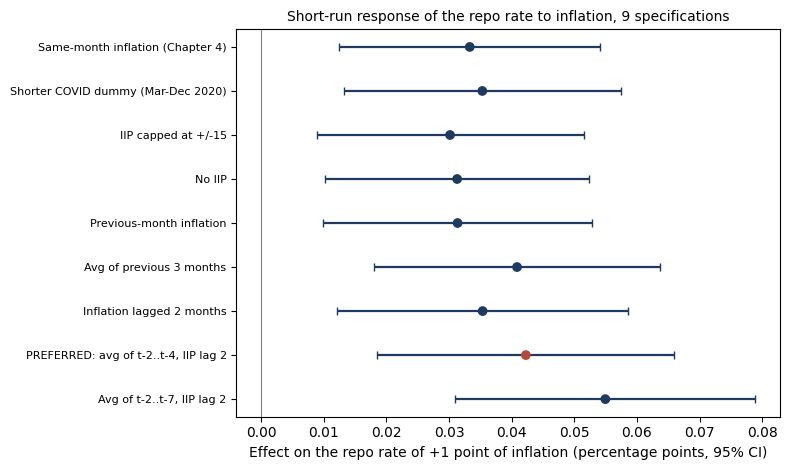

In [6]:
# Chapter 6: final specification, results table and chart. Paste into one Colab cell and run.
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, statsmodels.api as sm
import matplotlib.pyplot as plt

FOLDER = '/content/drive/MyDrive/rbi_macro/'
m = pd.read_csv(FOLDER + 'macro_monthly.csv', parse_dates=['month_end'], index_col='month_end')

m['covid'] = ((m.index >= '2020-03-31') & (m.index <= '2021-06-30')).astype(int)
m['covid_short'] = ((m.index >= '2020-03-31') & (m.index <= '2020-12-31')).astype(int)
m['repo_lag'] = m['repo_rate'].shift(1)
m['iip_cap'] = m['iip_growth'].clip(-15, 15)
# Information the RBI actually had: CPI for month t is published in mid t+1, so an early-month
# decision in month t can only use CPI up to month t-2.
m['infl_l1'] = m['cpi_infl'].shift(1);  m['infl_l2'] = m['cpi_infl'].shift(2)
m['infl_avg3'] = m['cpi_infl'].rolling(3).mean().shift(1)
m['infl_avg3_l2'] = m['cpi_infl'].rolling(3).mean().shift(2)
m['infl_avg6_l2'] = m['cpi_infl'].rolling(6).mean().shift(2)
m['iip_l2'] = m['iip_growth'].shift(2)

specs = [  # (label, regressors, inflation variable)
    ('Same-month inflation (Chapter 4)',          ['cpi_infl', 'iip_growth', 'covid'],      'cpi_infl'),
    ('Shorter COVID dummy (Mar-Dec 2020)',        ['cpi_infl', 'iip_growth', 'covid_short'], 'cpi_infl'),
    ('IIP capped at +/-15',                       ['cpi_infl', 'iip_cap', 'covid'],         'cpi_infl'),
    ('No IIP',                                    ['cpi_infl', 'covid'],                    'cpi_infl'),
    ('Previous-month inflation',                  ['infl_l1', 'iip_growth', 'covid'],       'infl_l1'),
    ('Avg of previous 3 months',                  ['infl_avg3', 'iip_growth', 'covid'],     'infl_avg3'),
    ('Inflation lagged 2 months',                 ['infl_l2', 'iip_l2', 'covid'],           'infl_l2'),
    ('PREFERRED: avg of t-2..t-4, IIP lag 2',     ['infl_avg3_l2', 'iip_l2', 'covid'],      'infl_avg3_l2'),
    ('Avg of t-2..t-7, IIP lag 2',                ['infl_avg6_l2', 'iip_l2', 'covid'],      'infl_avg6_l2'),
]

rows = []
for label, xs, key in specs:
    d = m.dropna(subset=['repo_rate', 'repo_lag'] + xs)
    r = sm.OLS(d['repo_rate'], sm.add_constant(d[['repo_lag'] + xs])).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
    b, rho = r.params[key], r.params['repo_lag']
    g = pd.Series(0.0, index=r.params.index); g[key] = 1 / (1 - rho); g['repo_lag'] = b / (1 - rho) ** 2
    se_lr = float(np.sqrt(g.values @ r.cov_params().values @ g.values)); lr = b / (1 - rho)
    lo, hi = r.conf_int().loc[key]
    rows.append(dict(spec=label, n=int(r.nobs), short_run=b, ci_low=lo, ci_high=hi, p=r.pvalues[key],
                     rho=rho, long_run=lr, lr_low=lr - 1.96 * se_lr, lr_high=lr + 1.96 * se_lr))
res = pd.DataFrame(rows)
res.round(3).to_csv(FOLDER + 'results_table.csv', index=False)
print(res.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(res))[::-1]
bold = res['spec'].str.startswith('PREFERRED')
ax.errorbar(res['short_run'], y, xerr=[res['short_run'] - res['ci_low'], res['ci_high'] - res['short_run']],
            fmt='none', ecolor='#1F3A5F', elinewidth=1.6, capsize=3)
ax.scatter(res['short_run'], y, c=np.where(bold, '#B5483A', '#1F3A5F'), zorder=3)
ax.axvline(0, c='grey', lw=.8); ax.set_yticks(y); ax.set_yticklabels(res['spec'], fontsize=8)
ax.set_xlabel('Effect on the repo rate of +1 point of inflation (percentage points, 95% CI)')
ax.set_title('Short-run response of the repo rate to inflation, 9 specifications', fontsize=10)
plt.tight_layout(); plt.savefig(FOLDER + 'short_run_response.png', dpi=140); plt.show()


In [7]:
# Chapter 7: two real-world checks. Run after the earlier chapters.
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.ardl import UECM
from statsmodels.miscmodels.ordinal_model import OrderedModel

m = pd.read_csv('/content/drive/MyDrive/rbi_macro/macro_monthly.csv', parse_dates=['month_end'], index_col='month_end')
m['covid'] = ((m.index >= '2020-03-31') & (m.index <= '2021-06-30')).astype(int)

# ---------- CHECK 2: do repo rate and inflation share a long-run trend? ----------
print('=== CHECK 2: unit roots and cointegration (n = %d months) ===' % len(m))
for c in ['repo_rate', 'cpi_infl']:
    for lab, s in [('level', m[c]), ('first diff', m[c].diff().dropna())]:
        print(f'{c:10s} {lab:10s} ADF p={adfuller(s, autolag="AIC")[1]:.3f} (H0 unit root)  KPSS p={kpss(s, regression="c", nlags="auto")[1]:.3f} (H0 stationary)')
for lab, xs in [('repo ~ infl', ['cpi_infl']), ('repo ~ infl + iip', ['cpi_infl', 'iip_growth'])]:
    t, p, crit = coint(m['repo_rate'], m[xs], trend='c', autolag='aic')
    print(f'Engle-Granger {lab:18s} stat={t:.2f}  p={p:.3f}  (5% critical value {crit[1]:.2f})')
for k in (1, 2):
    bt = UECM(m['repo_rate'], k, m[['cpi_infl']], k, trend='c').fit().bounds_test(case=3)
    c5 = bt.critical_values.loc[95.0]
    print(f'ARDL bounds test, {k} lag(s): F={bt.statistic:.2f}; 5% bounds I(0)={c5["lower"]:.2f}, I(1)={c5["upper"]:.2f}; p between {bt.pvalue["lower"]:.3f} and {bt.pvalue["upper"]:.3f}')

# ---------- CHECK 1: model the MPC decision at each meeting ----------
# Meeting calendar: 6 scheduled meetings a year (Feb, Apr, Jun, Aug, Oct, Dec), plus 2016 (Oct, Dec).
# Exceptions: 2020 had Feb, Mar, May, Aug, Oct, Dec (April and June moved to March and May);
# 2022 had Feb, Apr, May, Jun, Aug, Sep, Dec (October moved to September, May was added).
# Checked against the titles of RBI's 'Minutes of the Monetary Policy Committee Meeting' releases: 57 policy meetings, Oct 2016 to Dec 2025.
# RBI's count (63rd in Oct 2026) also includes an unscheduled meeting on 3 Nov 2022 with no rate decision, which is left out.
cal = [(2016, 10), (2016, 12)] + [(y, mo) for y in range(2017, 2026) for mo in (2, 4, 6, 8, 10, 12)]
cal.remove((2020, 4)); cal.remove((2020, 6)); cal.remove((2022, 10))
cal += [(2020, 3), (2020, 5), (2022, 5), (2022, 9)]
cal = sorted(cal)
print('\n=== CHECK 1: decision at each meeting ===')
print('meetings in calendar:', len(cal))
chg = m.index[m['repo_change'] != 0]
print('rate changes outside the calendar:', sorted(set(zip(chg.year, chg.month)) - set(cal)))

m['gap'] = m['cpi_infl'].rolling(3).mean().shift(2) - 4      # inflation known at meeting time, minus 4% target
m['iip_l2'] = m['iip_growth'].shift(2)
m['real_lag'] = m['repo_rate'].shift(1) - m['cpi_infl'].shift(2)
idx = [pd.Timestamp(y, mo, 1) + pd.offsets.MonthEnd(0) for y, mo in cal]
d = m.loc[idx].copy()
d['dec'] = np.sign(d['repo_change']).astype(int)               # -1 cut, 0 hold, +1 hike
d = d.dropna(subset=['gap', 'iip_l2', 'real_lag'])

def fit(d, xs, label):
    y = pd.Categorical(d['dec'], categories=[-1, 0, 1], ordered=True)
    mod = OrderedModel(y, d[xs], distr='logit')
    r = mod.fit(method='bfgs', disp=False, maxiter=1000, cov_type='HC1')
    k = len(xs)
    print(f'\n{label}\n n={int(r.nobs)}  cuts/holds/hikes = {(d.dec==-1).sum()}/{(d.dec==0).sum()}/{(d.dec==1).sum()}')
    print(pd.DataFrame({'coef': r.params[:k], 'odds ratio': np.exp(r.params[:k]), 'se (robust)': r.bse[:k], 'p': r.pvalues[:k]}).round(3).to_string())
    return r

r1 = fit(d, ['gap', 'iip_l2', 'covid'], 'Main: decision ~ inflation gap + IIP growth + covid')
fit(d, ['gap', 'iip_l2', 'covid', 'real_lag'], 'Add the lagged real policy rate')
fit(d[(d.index < '2020-02-01') | (d.index > '2021-12-31')].assign(covid=0).drop(columns='covid'), ['gap', 'iip_l2'], 'Drop all meetings from Feb 2020 to Dec 2021')
fit(d[d.index >= '2019-01-01'], ['gap', 'iip_l2', 'covid'], 'Only meetings from 2019 on')

# What the main model says, in probabilities (IIP at its mean, no covid)
base = pd.DataFrame({'gap': [-1.0, 0.0, 1.0, 2.0], 'iip_l2': d['iip_l2'].mean(), 'covid': 0})
p = r1.model.predict(r1.params, exog=base)
print('\nPredicted probabilities at average IIP growth (rows: inflation 1 below, at, 1 above, 2 above the 4% target)')
print(pd.DataFrame(p, columns=['cut', 'hold', 'hike'], index=['3%', '4%', '5%', '6%']).round(2).to_string())


=== CHECK 2: unit roots and cointegration (n = 111 months) ===
repo_rate  level      ADF p=0.351 (H0 unit root)  KPSS p=0.100 (H0 stationary)
repo_rate  first diff ADF p=0.014 (H0 unit root)  KPSS p=0.100 (H0 stationary)
cpi_infl   level      ADF p=0.664 (H0 unit root)  KPSS p=0.100 (H0 stationary)
cpi_infl   first diff ADF p=0.001 (H0 unit root)  KPSS p=0.100 (H0 stationary)
Engle-Granger repo ~ infl        stat=-2.26  p=0.394  (5% critical value -3.39)
Engle-Granger repo ~ infl + iip  stat=-1.78  p=0.819  (5% critical value -3.82)
ARDL bounds test, 1 lag(s): F=4.93; 5% bounds I(0)=3.80, I(1)=4.81; p between 0.013 and 0.044
ARDL bounds test, 2 lag(s): F=4.60; 5% bounds I(0)=3.80, I(1)=4.81; p between 0.019 and 0.061

=== CHECK 1: decision at each meeting ===
meetings in calendar: 57
rate changes outside the calendar: []

Main: decision ~ inflation gap + IIP growth + covid
 n=55  cuts/holds/hikes = 12/35/8
         coef  odds ratio  se (robust)      p
gap     1.196       3.306        0